# Matrix factorization: multiple seeds

Section 5.2 / Appendix E.2 of [Skip the Hessian, Keep the Rates](https://arxiv.org/abs/2602.08069).
This notebook follows the original sequence: run the methods for each seed,
average their histories, and plot the results. It uses the corrected oracle
with the revised equation (27):

$$F(U,V)=\frac12\|UV-M_{\mathrm{obs}}\|_F^2
  +\frac{\alpha}{2}(\|U\|_F^2+\|V\|_F^2)
  +\frac{\beta}{2}(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$

Here $U\in\mathbb{R}^{m\times r}$, $V\in\mathbb{R}^{r\times n}$, and
$(-U)_+=\max(-U,0)$ entrywise. The nonnegativity condition is penalized;
the factors are not constrained to be nonnegative at every iterate.

In [37]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from methods import gradient_method, mf_gladssn, mf_leapssn
from oracles_mat_fac import PositiveMatrixFactorization
from utils_new import run_methods, plot_figures

%matplotlib inline

## Parameters

| Variable | Meaning |
| --- | --- |
| `seeds_to_try` | Each seed fixes both the synthetic data and the starting factors. All methods use the same data and start within a seed. |
| `m`, `n`, `r` | Number of rows, number of columns, and factorization rank. |
| `noise` | Standard deviation of independent Gaussian noise added to `M_clean = U_true @ V_true`. The true factors have entries uniform on [0, 1). |
| `alpha`, `beta` | Ridge and nonnegativity weights in the objective above, each with a factor of 1/2. |
| `initial_factor_std` | Standard deviation of the zero-mean Gaussian entries of `U_0` and `V_0`. These starting factors can have negative entries. |
| `gradient_iterations`, `number_of_iterations` | Maximum outer iterations for gradient descent and each Newton method, respectively. |
| `initial_lambda` | Initial regularization passed as `H_0` to LeAP and GLAd. Both start with this actual shift in `Hessian + lambda * I`; GLAd subsequently scales its shift with the gradient norm raised to `p`. |
| `lss_method`, `lss_tol`, `lss_maxiters` | Linear subproblem solver, its requested relative tolerance, and its maximum iterations per solve. |
| `gn_exponents` | GLAd exponents to compare with Gauss-Newton; choose from the five exponents already run below. LeAP is also compared. |
| `plot_threshold` | Trim a displayed curve after its first value at or below this level. This is not a solver stopping criterion. |
| `SAVE_FIGURES` | Also save all six plots as PDFs when `True`. No history files are written. |

The settings below are a short check: one seed, 3,000 gradient steps, and
100 Newton steps. The original long run in the paper used 20 seeds, 3,000,000 gradient
steps, and 12,000 Newton steps; its recorded seed list is included below.

The original seven methods are gradient descent, LeAP-SSN, and GLAd-SSN with
`p = 0.2, 0.4, 0.5, 0.6, 0.8`. Newton methods use a fresh exact generalized
Hessian (`lazy_Hessians=False`, `use_gauss_newton=False`) and inexact MINRES
solves. No gradient or objective stopping tolerance is set. Newton methods
may exit early at zero gradient, numerical stagnation, or a failed search;
gradient descent runs to its budget. `run_methods` prints the exit status;
`iterations_exceeded` means the budget was used, not that convergence was verified.

The additional comparison runs LeAP and the selected GLAd exponents with
`use_gauss_newton=True`. The Gauss-Newton approximation retains ridge and
penalty curvature. Data, starting factors, initial regularization, iteration
budgets, and MINRES settings are identical to each exact-Hessian counterpart.


In [38]:
# Original recorded seeds (uncomment for the 20-seed experiment):
# seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
seeds_to_try = [549]

# Data and objective
m, n, r = 200, 100, 12
noise = 0.0
alpha, beta = 0.5, 200.0
initial_factor_std = 0.5

# Iteration budgets and regularization
gradient_iterations = 3_000       # Original long run: 3_000_000
number_of_iterations = 1500       # Original long run: 12_000
initial_lambda = 1024.0
lss_method = "minres"
lss_tol = 1e-9
lss_maxiters = 400
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Plotting and optional export
plot_threshold = 1e-10
SAVE_FIGURES = False

if not seeds_to_try or len(seeds_to_try) != len(set(seeds_to_try)):
    raise ValueError("Provide a nonempty list of distinct seeds.")
print("Trying seeds:", seeds_to_try)

Trying seeds: [549]


## Run the methods for each seed

As in the original notebook, `methods_to_run` lists each method with its
arguments and `all_seeds_histories[seed]` collects the results. Keep only
the four series needed for plotting (`func`, `time`, `grad_norm`, `penalty`)
as NumPy arrays to reduce memory use. Long runs still require more memory.
`penalty` includes the weight `beta/2`; `grad_norm` is the full objective gradient norm.

In [39]:
plot_keys = ("func", "time", "grad_norm", "penalty")
all_seeds_histories = {}
for seed in seeds_to_try:
    print("Running seed:", seed)
    np.random.seed(seed)

    # Ground truth
    U_true = np.random.rand(m, r)
    V_true = np.random.rand(n, r).T  # (r, n); preserve the previous random draw
    M_clean = U_true @ V_true

    # Noisy observed matrix
    M_obs = M_clean + noise * np.random.randn(m, n)

    # Gaussian starting factors, shared by every method for this seed.
    # Keep the original draw order while storing V with shape (r, n).
    initial_values = initial_factor_std * np.random.randn(m * r + n * r)
    U_0 = initial_values[:m*r].reshape(m, r)
    V_0 = initial_values[m*r:].reshape(n, r).T

    oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
    x_0 = oracle.pack(U_0, V_0)

    methods_to_run = {
        'Gradient Method': (
            gradient_method, (oracle, x_0),
            dict(
                max_iter=gradient_iterations,
                warnings=True,
            ),
        ),
        'LeAP-SSN': (
            mf_leapssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.2': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.2,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.4': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.4,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.5': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.5,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.6': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.6,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
        'GLAd-SSN, p=0.8': (
            mf_gladssn, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                H_0=initial_lambda,
                warnings=True,
                p=0.8,
                lss_tol=lss_tol,
                lss_maxiters=lss_maxiters,
                lss_method=lss_method,
                use_gauss_newton=False,
            ),
        ),
    }

    # Keep the original methods and add Gauss-Newton copies of selected ones.
    original_method_names = list(methods_to_run)
    gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]
    for method_name in gn_base_names:
        solver, args, options = methods_to_run[method_name]
        methods_to_run[f"{method_name} (GN)"] = (
            solver, args, dict(options, use_gauss_newton=True)
        )

    histories = run_methods(methods_to_run, oracle, x_0)
    all_seeds_histories[seed] = {
        method_name: {measure: np.asarray(history[measure]) for measure in plot_keys}
        for method_name, history in histories.items()
    }
    del histories  # Release the solver's additional diagnostic series.

Running seed: 549

Running Gradient Method...
Status: iterations_exceeded
Time: 1.288 s

Running LeAP-SSN...
Iteration  0
Iteration  500
W: numerical_stagnation, 525 iters -- returning the last accepted iterate
No of backtracks:  547
Status: numerical_stagnation, 525 iters
Time: 44.081 s

Running GLAd-SSN, p=0.2...
Iteration  0
Iteration  500
Iteration  1000
W: numerical_stagnation, 1043 iters -- returning the last accepted iterate
No of backtracks:  1059
Status: numerical_stagnation, 1043 iters
Time: 81.766 s

Running GLAd-SSN, p=0.4...
Iteration  0
Iteration  500
Iteration  1000
W: numerical_stagnation, 1290 iters -- returning the last accepted iterate
No of backtracks:  1320
Status: numerical_stagnation, 1290 iters
Time: 111.121 s

Running GLAd-SSN, p=0.5...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
No of backtracks:  1498
Status: iterations_exceeded
Time: 122.558 s

Running GLAd-SSN, p=0.6...
Iteration  0
Iteration  500
Iteration  1000
Iteration  1500
No of backtr

## Average over the seeds

Use the original `add_common` calculation: sum matching iterations and
divide by the number of seeds. Every mean includes all seeds, so a method's
curve ends at its shortest run. Check the printed exit statuses above.
Runtime plots pair the mean metric with the mean time at the same iteration.

In [40]:
template_seed = seeds_to_try[0]
averaged_history = {
    method_name: {
        measure: np.zeros_like(history[measure], dtype=float)
        for measure in plot_keys
    }
    for method_name, history in all_seeds_histories[template_seed].items()
}

def add_common(a, b):
    """Add arrays only through the shorter run's last recorded iteration."""
    n = min(len(a), len(b))
    return a[:n] + b[:n]

for seed in seeds_to_try:
    for method_name, history in all_seeds_histories[seed].items():
        for measure in plot_keys:
            averaged_history[method_name][measure] = add_common(
                averaged_history[method_name][measure], history[measure]
            )

for method_name in averaged_history:
    for measure in plot_keys:
        averaged_history[method_name][measure] /= len(seeds_to_try)
    print(method_name, ": averaging all seeds through iteration",
          len(averaged_history[method_name]["func"]) - 1)

Gradient Method : averaging all seeds through iteration 3000
LeAP-SSN : averaging all seeds through iteration 525
GLAd-SSN, p=0.2 : averaging all seeds through iteration 1043
GLAd-SSN, p=0.4 : averaging all seeds through iteration 1290
GLAd-SSN, p=0.5 : averaging all seeds through iteration 1500
GLAd-SSN, p=0.6 : averaging all seeds through iteration 1500
GLAd-SSN, p=0.8 : averaging all seeds through iteration 1500
LeAP-SSN (GN) : averaging all seeds through iteration 1500
GLAd-SSN, p=0.2 (GN) : averaging all seeds through iteration 1500
GLAd-SSN, p=0.5 (GN) : averaging all seeds through iteration 1500


## Plots

Use the original colors and `plot_figures` layout via `utils_new`.
`mn_func` is the best observed mean objective, not a known global optimum.
Plot the mean objective minus this reference, the mean gradient norm, and
the mean weighted penalty. The iteration axis shows up to
`number_of_iterations`; the runtime axis includes each method's longer run.

These first three plots retain the original seven methods and their objective reference.


In [41]:
histories = {name: averaged_history[name] for name in original_method_names}
#line_widths = [2.5] * len(histories)
line_widths = [2.0] * len(histories)
line_styles = ["-"] * len(histories)
colors = ["#E8601C", "black", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF"]
mn_func = min(np.min(history["func"]) for history in histories.values())
figures = {}

Last Mean objective - best observed mean of Gradient Method: 3.0146501970151007
Last Mean objective - best observed mean of LeAP-SSN: 0.40512875180058927
Last Mean objective - best observed mean of GLAd-SSN, p=0.2: 0.06938391835677749
Last Mean objective - best observed mean of GLAd-SSN, p=0.4: 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.5: 0.01641737674236765
Last Mean objective - best observed mean of GLAd-SSN, p=0.6: 6.459494545651978e-05
Last Mean objective - best observed mean of GLAd-SSN, p=0.8: 0.0006082811644887443


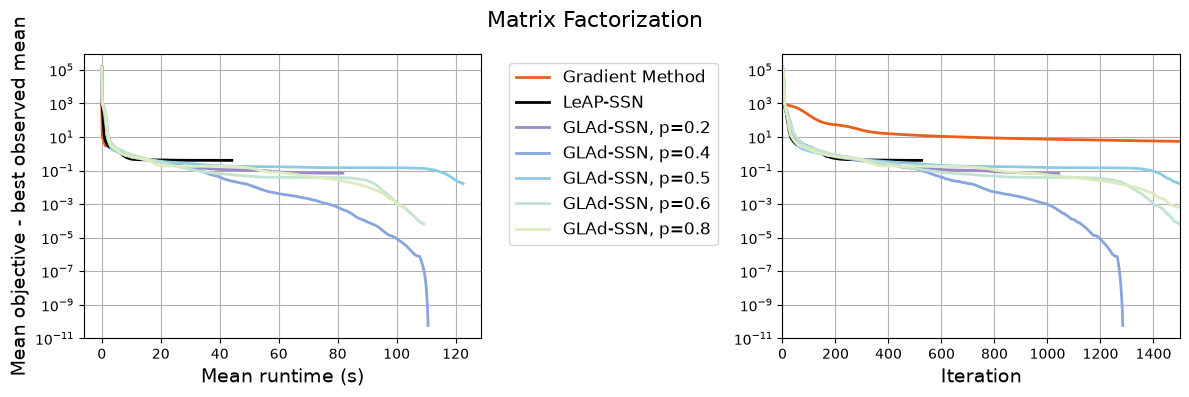

Last Mean gradient norm of Gradient Method: 1.0579602366452587
Last Mean gradient norm of LeAP-SSN: 7.88833704340772e-09
Last Mean gradient norm of GLAd-SSN, p=0.2: 9.291586005526753e-10
Last Mean gradient norm of GLAd-SSN, p=0.4: 3.6387895031419586e-07
Last Mean gradient norm of GLAd-SSN, p=0.5: 0.013485957369361475
Last Mean gradient norm of GLAd-SSN, p=0.6: 0.00046655533976154025
Last Mean gradient norm of GLAd-SSN, p=0.8: 0.0016094745991597776


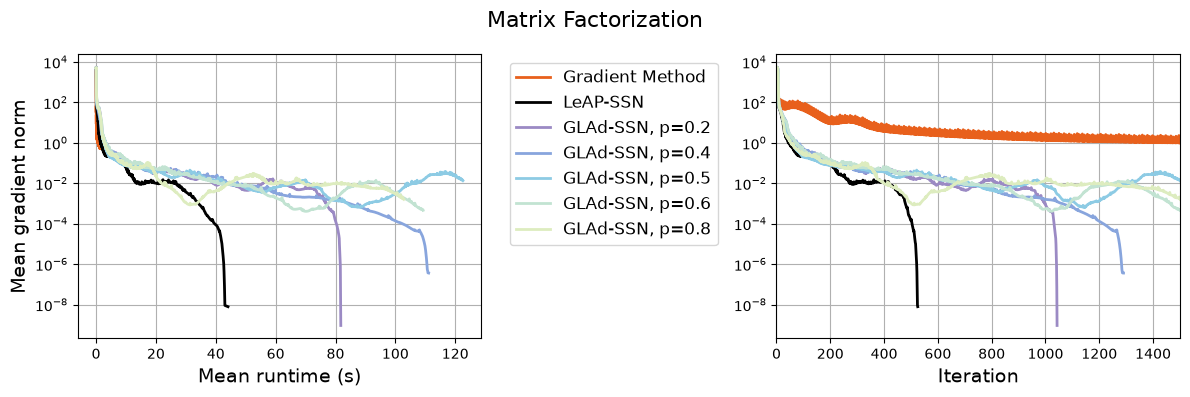

Last Mean penalty of Gradient Method: 0.16245596140663993
Last Mean penalty of LeAP-SSN: 0.021047373409274643
Last Mean penalty of GLAd-SSN, p=0.2: 0.0031356575426229223
Last Mean penalty of GLAd-SSN, p=0.4: 2.4706583644908684e-12
Last Mean penalty of GLAd-SSN, p=0.5: 0.0007578701419417247
Last Mean penalty of GLAd-SSN, p=0.6: 2.8851623909213945e-06
Last Mean penalty of GLAd-SSN, p=0.8: 2.7072782254539354e-05


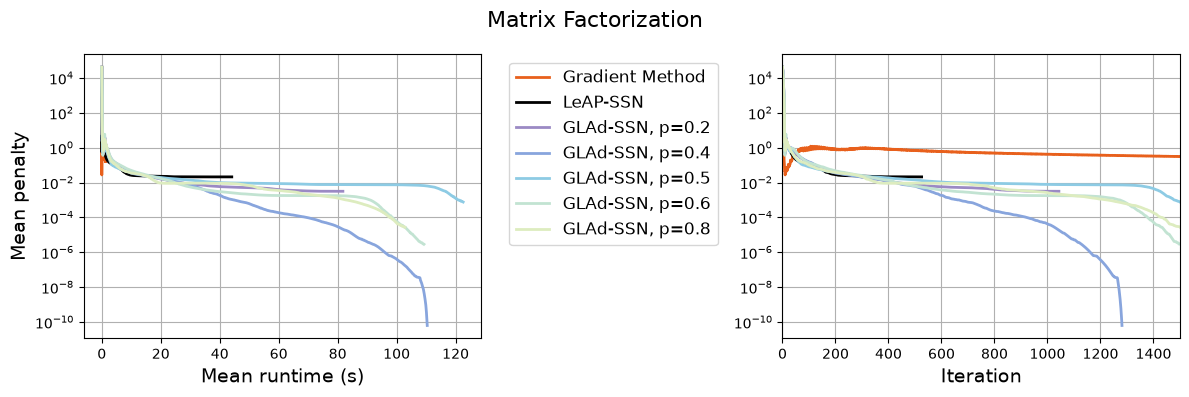

In [42]:
figures["func"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=mn_func, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="func", which_measure_2="func",
    ylabel="Mean objective - best observed mean",
)
plt.show()
plt.close(figures["func"])


figures["grad_norm"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="grad_norm", which_measure_2="grad_norm",
    ylabel="Mean gradient norm",
)
plt.show()
plt.close(figures["grad_norm"])


figures["penalty"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="penalty", which_measure_2="penalty",
    ylabel="Mean penalty",
)
plt.show()
plt.close(figures["penalty"])

## Additional comparison: exact Hessian and Gauss-Newton

Keep gradient descent as the baseline, then compare LeAP and the selected GLAd
exponents. Solid lines use the exact generalized Hessian; dashed lines use
Gauss-Newton, with the same color for each pair. All curves use the same seed
data and starting factors. The objective reference is the best observed mean
among the methods shown in these additional plots, not a known global optimum.
The three original plots above keep their own reference.


Last Mean objective - best observed mean of Gradient Method: 3.0145543577193052
Last Mean objective - best observed mean of LeAP-SSN (exact): 0.4050329125047938
Last Mean objective - best observed mean of LeAP-SSN (GN): 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (exact): 0.069288079060982
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (GN): 0.07284062075757447
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (exact): 0.016321537446572165
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (GN): 8.994504082693311e-05


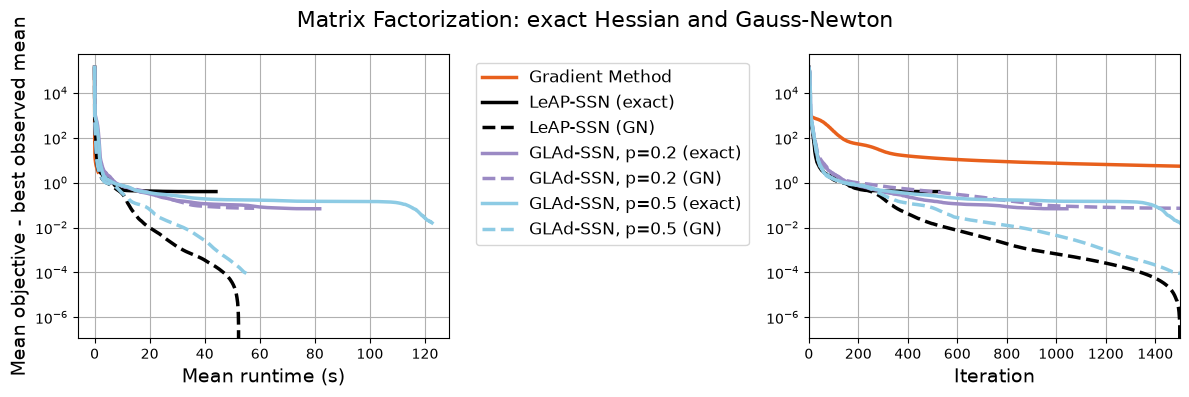

Last Mean gradient norm of Gradient Method: 1.0579602366452587
Last Mean gradient norm of LeAP-SSN (exact): 7.88833704340772e-09
Last Mean gradient norm of LeAP-SSN (GN): 0.0007986298457602043
Last Mean gradient norm of GLAd-SSN, p=0.2 (exact): 9.291586005526753e-10
Last Mean gradient norm of GLAd-SSN, p=0.2 (GN): 0.004903156760102257
Last Mean gradient norm of GLAd-SSN, p=0.5 (exact): 0.013485957369361475
Last Mean gradient norm of GLAd-SSN, p=0.5 (GN): 0.0011123615930107378


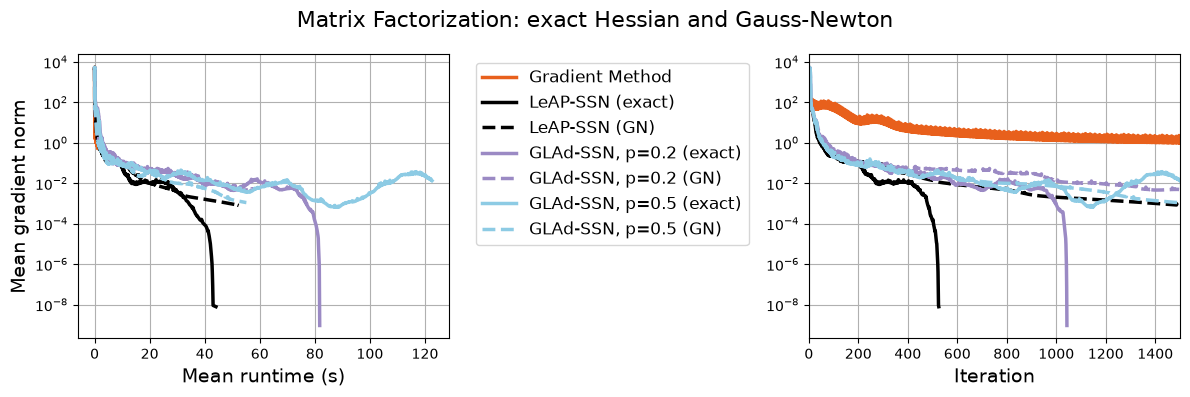

Last Mean penalty of Gradient Method: 0.16245596140663993
Last Mean penalty of LeAP-SSN (exact): 0.021047373409274643
Last Mean penalty of LeAP-SSN (GN): 4.328486030054683e-06
Last Mean penalty of GLAd-SSN, p=0.2 (exact): 0.0031356575426229223
Last Mean penalty of GLAd-SSN, p=0.2 (GN): 0.0035999397509878578
Last Mean penalty of GLAd-SSN, p=0.5 (exact): 0.0007578701419417247
Last Mean penalty of GLAd-SSN, p=0.5 (GN): 8.48319336419206e-06


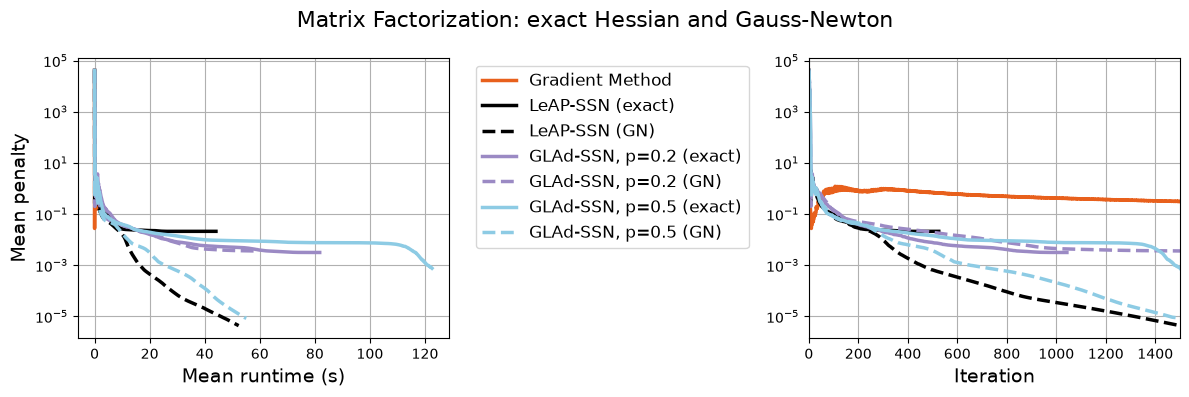

In [43]:
# Select matching exact/Gauss-Newton pairs without changing the original plots.
comparison_names = ["Gradient Method"]
comparison_colors = [colors[0]]
comparison_styles = ["-"]
for method_name in gn_base_names:
    color = colors[original_method_names.index(method_name)]
    comparison_names.extend([method_name, f"{method_name} (GN)"])
    comparison_colors.extend([color, color])
    comparison_styles.extend(["-", "--"])

comparison_histories = [averaged_history[name] for name in comparison_names]
comparison_labels = [
    name if name == "Gradient Method" or name.endswith(" (GN)") else f"{name} (exact)"
    for name in comparison_names
]
comparison_reference = min(np.min(history["func"]) for history in comparison_histories)

for measure, reference, ylabel in [
    ("func", comparison_reference, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        comparison_histories, comparison_labels,
        colors=comparison_colors, linewidths=[2.5] * len(comparison_names),
        linestyles=comparison_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization: exact Hessian and Gauss-Newton",
        max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[f"{measure}_gn"] = fig
    plt.show()
    plt.close(fig)


## Optional figure export

Set `SAVE_FIGURES=True` to save all six PDFs in a new, Git-ignored local folder.
By default, the notebook only displays the plots.

In [44]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "_diagnostics_archive" / "multiple_new" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, fig in figures.items():
        fig.savefig(output_dir / f"{measure}.pdf", bbox_inches="tight")
    print("Saved figures to", output_dir)